In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib xgboost

Note: you may need to restart the kernel to use updated packages.


In [11]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

print("Libraries imported successfully.")
print("XGBoost available:", XGBOOST_AVAILABLE)

Libraries imported successfully.
XGBoost available: True


In [12]:
PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DIR = PROJECT_DIR / "data" / "features"
REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
CHART_DIR = PROJECT_DIR / "outputs" / "charts"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
FORECAST_DIR = PROJECT_DIR / "data" / "forecasts"

for folder in [
    FEATURE_DIR,
    REPORT_DIR,
    CHART_DIR,
    MODEL_DIR,
    FORECAST_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT"
]

TARGET_COLUMN = "target_next_close"
CURRENT_PRICE_COLUMN = "close"

N_SPLITS = 6
INITIAL_TRAIN_RATIO = 0.80

print("Project:", PROJECT_DIR)
print("Feature directory:", FEATURE_DIR)
print("Instruments:", len(INSTRUMENTS))

Project: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Feature directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\features
Instruments: 10


In [13]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "MAPE": np.nan,
            "R2": np.nan,
            "Directional_Accuracy": np.nan
        }

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    r2 = (
        r2_score(actual, predicted)
        if len(actual) > 1
        else np.nan
    )

    # Compare predicted and actual movement against
    # the current closing price.
    # Direction is measured relative to the previous close.
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    }


def calculate_directional_accuracy(
    actual,
    predicted,
    current_price
):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    current_price = np.asarray(current_price, dtype=float)

    valid = (
        np.isfinite(actual)
        & np.isfinite(predicted)
        & np.isfinite(current_price)
    )

    actual = actual[valid]
    predicted = predicted[valid]
    current_price = current_price[valid]

    if len(actual) == 0:
        return np.nan

    actual_direction = np.sign(actual - current_price)
    predicted_direction = np.sign(predicted - current_price)

    return np.mean(
        actual_direction == predicted_direction
    ) * 100


def evaluate_predictions(actual, predicted, current_price):
    metrics = calculate_metrics(actual, predicted)

    metrics["Directional_Accuracy"] = (
        calculate_directional_accuracy(
            actual,
            predicted,
            current_price
        )
    )

    return metrics


print("Evaluation functions created.")

Evaluation functions created.


In [14]:
market_datasets = {}
dataset_summary = []

EXCLUDED_COLUMNS = {
    "date",
    "symbol",
    "instrument",
    "target_next_close",
    "target_next_return",
    "target_next_direction"
}

def prepare_dataset(symbol):
    file_path = FEATURE_DIR / f"{symbol}_model_ready.csv"

    if not file_path.exists():
        print(f"Missing dataset: {file_path}")
        return None

    df = pd.read_csv(file_path)

    if "date" in df.columns:
        df["date"] = pd.to_datetime(
            df["date"],
            errors="coerce"
        )
        df = df.sort_values("date")

    if TARGET_COLUMN not in df.columns:
        print(f"{symbol}: Missing target column {TARGET_COLUMN}")
        return None

    if CURRENT_PRICE_COLUMN not in df.columns:
        print(f"{symbol}: Missing current close column")
        return None

    # Keep only valid target and current-price rows.
    df[TARGET_COLUMN] = pd.to_numeric(
        df[TARGET_COLUMN],
        errors="coerce"
    )

    df[CURRENT_PRICE_COLUMN] = pd.to_numeric(
        df[CURRENT_PRICE_COLUMN],
        errors="coerce"
    )

    df = df.replace([np.inf, -np.inf], np.nan)

    df = df.dropna(
        subset=[TARGET_COLUMN, CURRENT_PRICE_COLUMN]
    ).reset_index(drop=True)

    # Numeric features only.
    feature_columns = [
        col for col in df.select_dtypes(include=np.number).columns
        if col not in EXCLUDED_COLUMNS
    ]

    # Do not accidentally include any future-derived target.
    feature_columns = [
        col for col in feature_columns
        if not col.startswith("target_")
        and not col.startswith("next_")
    ]

    # Current close is allowed as an input because it is known
    # at prediction time.
    if not feature_columns:
        print(f"{symbol}: No usable numeric features.")
        return None

    X = df[feature_columns].copy()
    y = df[TARGET_COLUMN].copy()
    current_price = df[CURRENT_PRICE_COLUMN].copy()

    # Remove features that contain no usable information.
    usable_columns = [
        col for col in X.columns
        if X[col].notna().any()
    ]

    X = X[usable_columns]

    # Retain rows with at least one valid feature.
    valid_rows = X.notna().any(axis=1)

    X = X.loc[valid_rows].reset_index(drop=True)
    y = y.loc[valid_rows].reset_index(drop=True)
    current_price = current_price.loc[valid_rows].reset_index(drop=True)
    df = df.loc[valid_rows].reset_index(drop=True)

    return {
        "data": df,
        "X": X,
        "y": y,
        "current_price": current_price,
        "features": list(X.columns)
    }


for symbol in INSTRUMENTS:
    result = prepare_dataset(symbol)

    if result is None:
        continue

    market_datasets[symbol] = result

    dataset_summary.append({
        "Instrument": symbol,
        "Rows": len(result["X"]),
        "Features": len(result["features"]),
        "Start_Date": (
            result["data"]["date"].min()
            if "date" in result["data"].columns
            else None
        ),
        "End_Date": (
            result["data"]["date"].max()
            if "date" in result["data"].columns
            else None
        )
    })

dataset_summary_df = pd.DataFrame(dataset_summary)

display(dataset_summary_df)

print(
    f"\nSuccessfully loaded "
    f"{len(market_datasets)} instruments."
)

,Instrument,Rows,Features,Start_Date,End_Date
0,NIFTY50,1034,62,2022-09-09,2026-11-20
1,BANKNIFTY,1033,62,2022-09-09,2026-11-20
2,RELIANCE,1037,62,2022-09-09,2026-11-20
3,TCS,1037,62,2022-09-09,2026-11-20
4,HDFCBANK,1037,62,2022-09-09,2026-11-20
5,INFY,1037,62,2022-09-09,2026-11-20
6,ICICIBANK,1037,62,2022-09-09,2026-11-20
7,SBIN,1037,62,2022-09-09,2026-11-20
8,ITC,1037,62,2022-09-09,2026-11-20
9,LT,1037,62,2022-09-09,2026-11-20



Successfully loaded 10 instruments.


In [15]:
def create_models():
    models = {
        "Linear Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),

        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(
                max_depth=8,
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42
            ))
        ]),

        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=100,
                max_depth=12,
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=1
            ))
        ]),

        "Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42
            ))
        ])
    }

    if XGBOOST_AVAILABLE:
        models["XGBoost"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=1,
                verbosity=0
            ))
        ])

    return models


models = create_models()

print("Models configured:")
for model_name in models:
    print("-", model_name)

Models configured:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost


In [16]:
def generate_walk_forward_folds(
    number_of_rows,
    n_splits=6,
    initial_train_ratio=0.80
):
    """
    Creates chronological expanding-window folds.

    Each validation block is non-overlapping.
    The training data always comes before validation data.
    """

    initial_train_size = int(
        number_of_rows * initial_train_ratio
    )

    remaining_rows = number_of_rows - initial_train_size

    if initial_train_size < 300:
        raise ValueError(
            "Insufficient initial training observations. "
            "At least 300 are required."
        )

    if remaining_rows < n_splits:
        raise ValueError(
            "Not enough observations for the requested folds."
        )

    validation_indices = np.array_split(
        np.arange(initial_train_size, number_of_rows),
        n_splits
    )

    folds = []

    for fold_number, validation_idx in enumerate(
        validation_indices,
        start=1
    ):
        if len(validation_idx) == 0:
            continue

        train_end = validation_idx[0]

        train_idx = np.arange(0, train_end)

        folds.append({
            "fold": fold_number,
            "train_idx": train_idx,
            "validation_idx": validation_idx
        })

    return folds


# Preview fold sizes for NIFTY50.
if "NIFTY50" in market_datasets:
    nifty_rows = len(market_datasets["NIFTY50"]["X"])

    preview_folds = generate_walk_forward_folds(
        nifty_rows,
        n_splits=N_SPLITS,
        initial_train_ratio=INITIAL_TRAIN_RATIO
    )

    for fold in preview_folds:
        print(
            f"Fold {fold['fold']}: "
            f"Training={len(fold['train_idx'])}, "
            f"Validation={len(fold['validation_idx'])}"
        )

Fold 1: Training=827, Validation=35
Fold 2: Training=862, Validation=35
Fold 3: Training=897, Validation=35
Fold 4: Training=932, Validation=34
Fold 5: Training=966, Validation=34
Fold 6: Training=1000, Validation=34


In [17]:
walk_forward_results = []
walk_forward_predictions = []
feature_importance_records = []

for symbol, dataset in market_datasets.items():

    print("\n" + "=" * 70)
    print(f"PROCESSING: {symbol}")
    print("=" * 70)

    X = dataset["X"]
    y = dataset["y"]
    current_price = dataset["current_price"]
    dates = (
        dataset["data"]["date"]
        if "date" in dataset["data"].columns
        else pd.Series(range(len(X)))
    )

    folds = generate_walk_forward_folds(
        len(X),
        n_splits=N_SPLITS,
        initial_train_ratio=INITIAL_TRAIN_RATIO
    )

    for fold in folds:

        fold_number = fold["fold"]
        train_idx = fold["train_idx"]
        validation_idx = fold["validation_idx"]

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]

        X_validation = X.iloc[validation_idx]
        y_validation = y.iloc[validation_idx]

        current_validation_price = (
            current_price.iloc[validation_idx]
        )

        validation_dates = dates.iloc[validation_idx]

        print(
            f"\n{symbol} | Fold {fold_number} | "
            f"Train: {len(train_idx)} | "
            f"Validation: {len(validation_idx)}"
        )

        # Persistence baseline:
        # Predict tomorrow's close as today's close.
        baseline_predictions = current_validation_price.values

        baseline_metrics = evaluate_predictions(
            y_validation.values,
            baseline_predictions,
            current_validation_price.values
        )

        walk_forward_results.append({
            "Instrument": symbol,
            "Fold": fold_number,
            "Model": "Persistence Baseline",
            "Train_Size": len(train_idx),
            "Validation_Size": len(validation_idx),
            **baseline_metrics
        })

        for model_name, model in models.items():

            try:
                model.fit(X_train, y_train)

                predictions = model.predict(X_validation)

                metrics = evaluate_predictions(
                    y_validation.values,
                    predictions,
                    current_validation_price.values
                )

                walk_forward_results.append({
                    "Instrument": symbol,
                    "Fold": fold_number,
                    "Model": model_name,
                    "Train_Size": len(train_idx),
                    "Validation_Size": len(validation_idx),
                    **metrics
                })

                for i, predicted_value in enumerate(predictions):
                    walk_forward_predictions.append({
                        "Instrument": symbol,
                        "Fold": fold_number,
                        "Date": validation_dates.iloc[i],
                        "Model": model_name,
                        "Current_Close": current_validation_price.iloc[i],
                        "Actual_Next_Close": y_validation.iloc[i],
                        "Predicted_Next_Close": predicted_value,
                        "Prediction_Error": (
                            y_validation.iloc[i] - predicted_value
                        )
                    })

                # Extract feature importance for tree-based models.
                fitted_model = model.named_steps["model"]

                if hasattr(fitted_model, "feature_importances_"):
                    importance_values = (
                        fitted_model.feature_importances_
                    )

                    for feature, importance in zip(
                        X.columns,
                        importance_values
                    ):
                        feature_importance_records.append({
                            "Instrument": symbol,
                            "Fold": fold_number,
                            "Model": model_name,
                            "Feature": feature,
                            "Importance": importance
                        })

                print(
                    f"{model_name}: completed | "
                    f"RMSE={metrics['RMSE']:.4f}"
                )

            except Exception as error:
                print(
                    f"{model_name}: FAILED | {error}"
                )

print("\nWalk-forward validation completed.")


PROCESSING: NIFTY50

NIFTY50 | Fold 1 | Train: 827 | Validation: 35
Linear Regression: completed | RMSE=343.1135
Decision Tree: completed | RMSE=294.5661
Random Forest: completed | RMSE=256.6331
Gradient Boosting: completed | RMSE=259.7287
XGBoost: completed | RMSE=257.1962

NIFTY50 | Fold 2 | Train: 862 | Validation: 35
Linear Regression: completed | RMSE=385.2959
Decision Tree: completed | RMSE=421.1847
Random Forest: completed | RMSE=337.4853
Gradient Boosting: completed | RMSE=329.9761
XGBoost: completed | RMSE=330.1019

NIFTY50 | Fold 3 | Train: 897 | Validation: 35
Linear Regression: completed | RMSE=213.7549
Decision Tree: completed | RMSE=299.4526
Random Forest: completed | RMSE=215.9528
Gradient Boosting: completed | RMSE=214.4318
XGBoost: completed | RMSE=211.0777

NIFTY50 | Fold 4 | Train: 932 | Validation: 34
Linear Regression: completed | RMSE=172.5505
Decision Tree: completed | RMSE=324.5615
Random Forest: completed | RMSE=183.7624
Gradient Boosting: completed | RMSE=178

In [18]:
walk_forward_df = pd.DataFrame(walk_forward_results)
walk_forward_predictions_df = pd.DataFrame(
    walk_forward_predictions
)
feature_importance_df = pd.DataFrame(
    feature_importance_records
)

if walk_forward_df.empty:
    raise RuntimeError(
        "No evaluation results were generated. "
        "Check the previous cell for errors."
    )

walk_forward_df.to_csv(
    REPORT_DIR / "walk_forward_fold_results.csv",
    index=False
)

walk_forward_predictions_df.to_csv(
    FORECAST_DIR / "walk_forward_predictions.csv",
    index=False
)

feature_importance_df.to_csv(
    REPORT_DIR / "walk_forward_feature_importance.csv",
    index=False
)

print("Evaluation records:", len(walk_forward_df))
print("Prediction records:", len(walk_forward_predictions_df))

print("\nNumber of folds evaluated per instrument:")
display(
    walk_forward_df.groupby("Instrument")["Fold"].nunique()
)

print("\nFold-level results:")
display(walk_forward_df.head(20))

Evaluation records: 360
Prediction records: 10390

Number of folds evaluated per instrument:


Instrument
BANKNIFTY    6
HDFCBANK     6
ICICIBANK    6
INFY         6
ITC          6
LT           6
NIFTY50      6
RELIANCE     6
SBIN         6
TCS          6
Name: Fold, dtype: int64


Fold-level results:


,Instrument,Fold,Model,Train_Size,Validation_Size,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,NIFTY50,1,Persistence Baseline,827,35,203.335658,247.642035,0.810497,0.782493,0.000000
1,NIFTY50,1,Linear Regression,827,35,255.168623,343.113519,1.022535,0.582458,54.285714
2,NIFTY50,1,Decision Tree,827,35,236.901658,294.566081,0.938011,0.692256,45.714286
3,NIFTY50,1,Random Forest,827,35,208.837701,256.633082,0.830839,0.766412,54.285714
4,NIFTY50,1,Gradient Boosting,827,35,208.368173,259.728700,0.828540,0.760743,45.714286
5,NIFTY50,1,XGBoost,827,35,209.128516,257.196215,0.832136,0.765386,48.571429
6,NIFTY50,2,Persistence Baseline,862,35,274.705636,335.436581,1.171246,0.702234,0.000000
7,NIFTY50,2,Linear Regression,862,35,272.196464,385.295894,1.165846,0.607136,62.857143
8,NIFTY50,2,Decision Tree,862,35,331.235516,421.184662,1.412825,0.530540,54.285714
9,NIFTY50,2,Random Forest,862,35,260.467935,337.485310,1.111500,0.698586,54.285714


In [19]:
metric_columns = [
    "MAE",
    "RMSE",
    "MAPE",
    "R2",
    "Directional_Accuracy"
]

model_summary = (
    walk_forward_df
    .groupby(["Instrument", "Model"])[metric_columns]
    .agg(["mean", "std"])
    .reset_index()
)

model_summary.columns = [
    "_".join(
        str(part) for part in column if str(part)
    ).rstrip("_")
    if isinstance(column, tuple)
    else column
    for column in model_summary.columns
]

model_summary.to_csv(
    REPORT_DIR / "machine_learning_walk_forward_summary.csv",
    index=False
)

display(model_summary)

# Select the best model per instrument using mean RMSE.
best_models = (
    walk_forward_df
    .groupby(["Instrument", "Model"])["RMSE"]
    .mean()
    .reset_index()
    .sort_values(["Instrument", "RMSE"])
    .groupby("Instrument")
    .first()
    .reset_index()
    .rename(columns={
        "Model": "Best_Model",
        "RMSE": "Mean_RMSE"
    })
)

best_models.to_csv(
    REPORT_DIR / "best_machine_learning_models.csv",
    index=False
)

print("Best model per instrument:")
display(best_models)

,Instrument,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_mean,MAPE_std,R2_mean,R2_std,Directional_Accuracy_mean,Directional_Accuracy_std
0,BANKNIFTY,Decision Tree,731.724841,214.808311,947.541243,305.495482,1.284857,0.363536,0.386174,0.556950,46.386555,8.162601
1,BANKNIFTY,Gradient Boosting,669.737914,291.391297,882.450945,387.234904,1.166183,0.485896,0.532540,0.413117,49.803922,9.101374
2,BANKNIFTY,Linear Regression,592.967375,108.093641,755.391672,139.910826,1.047851,0.206222,0.511783,0.621296,49.229692,6.407841
3,BANKNIFTY,Persistence Baseline,511.130521,172.946727,664.688814,226.332996,0.903648,0.324024,0.675160,0.357920,0.000000,0.000000
4,BANKNIFTY,Random Forest,661.748047,256.154344,862.588912,338.510892,1.155938,0.436410,0.541587,0.396369,47.899160,14.376577
5,BANKNIFTY,XGBoost,675.281725,302.428590,881.020159,398.001881,1.175152,0.508698,0.548799,0.376961,47.380952,10.688655
6,HDFCBANK,Decision Tree,12.392552,2.544570,15.516967,2.892966,1.590755,0.335566,0.540493,0.346319,51.988796,8.008834
7,HDFCBANK,Gradient Boosting,11.424834,2.665915,14.543990,3.378570,1.471751,0.346056,0.604676,0.298120,47.170868,7.141308
8,HDFCBANK,Linear Regression,10.174740,2.642004,12.849879,2.970042,1.295623,0.315423,0.697672,0.198646,45.728291,9.445680
9,HDFCBANK,Persistence Baseline,9.513191,2.746064,12.178994,3.272367,1.218374,0.361933,0.724393,0.200633,0.952381,2.332847


Best model per instrument:


,Instrument,Best_Model,Mean_RMSE
0,BANKNIFTY,Persistence Baseline,664.688814
1,HDFCBANK,Persistence Baseline,12.178994
2,ICICIBANK,Persistence Baseline,18.621060
3,INFY,Persistence Baseline,24.959613
4,ITC,Persistence Baseline,3.966633
5,LT,Persistence Baseline,62.839851
6,NIFTY50,Persistence Baseline,222.340956
7,RELIANCE,Persistence Baseline,20.105336
8,SBIN,Persistence Baseline,16.918146
9,TCS,Persistence Baseline,48.638510


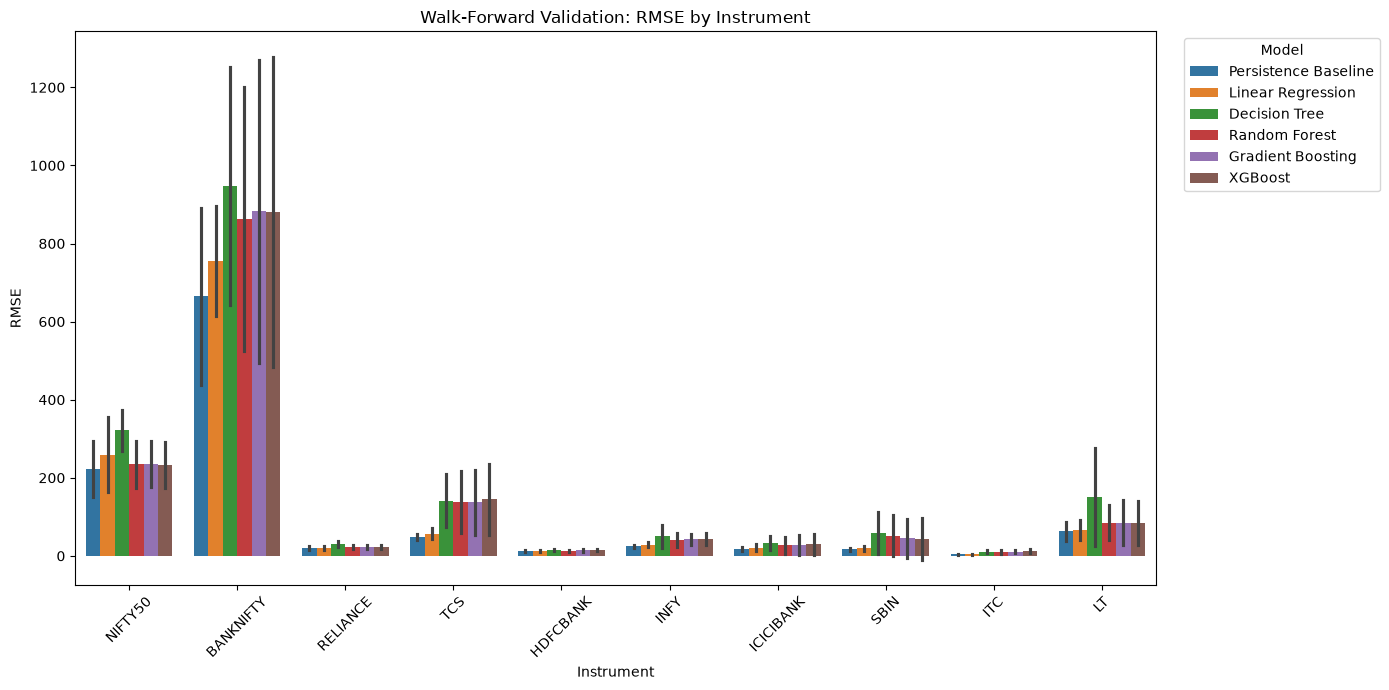

In [20]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=walk_forward_df,
    x="Instrument",
    y="RMSE",
    hue="Model",
    errorbar="sd"
)

plt.title("Walk-Forward Validation: RMSE by Instrument")
plt.xlabel("Instrument")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "walk_forward_rmse_comparison.png",
    dpi=300
)

plt.show()

C:\Users\adity\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


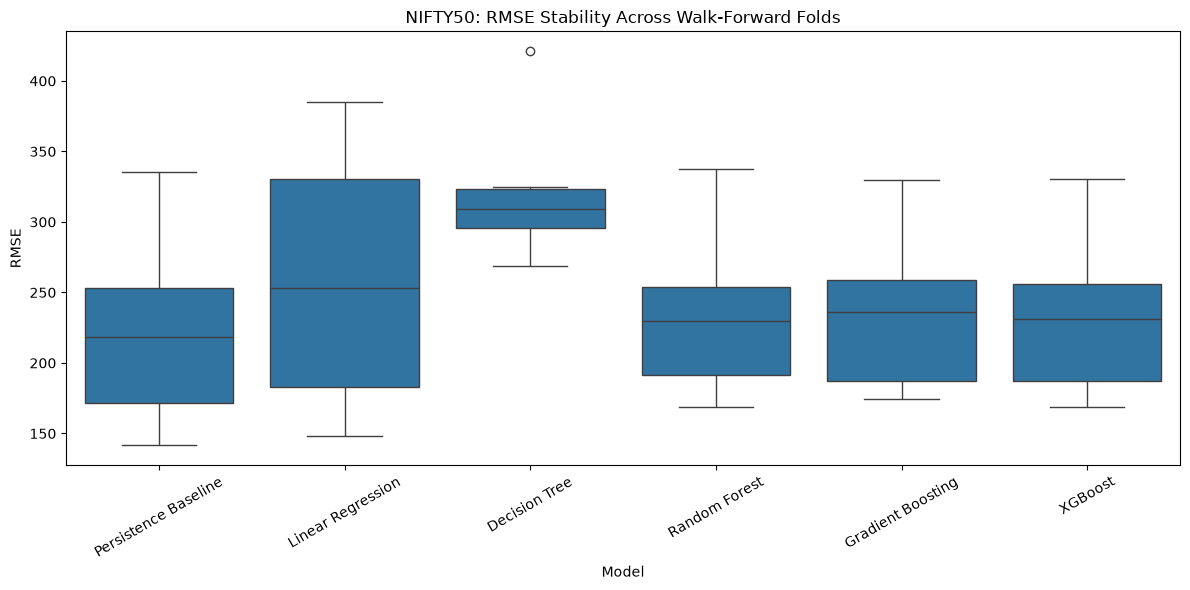

In [21]:
# NIFTY50 model comparison
nifty_results = walk_forward_df[
    walk_forward_df["Instrument"] == "NIFTY50"
]

if not nifty_results.empty:

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=nifty_results,
        x="Model",
        y="RMSE"
    )

    plt.title("NIFTY50: RMSE Stability Across Walk-Forward Folds")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "nifty50_walk_forward_rmse_stability.png",
        dpi=300
    )

    plt.show()

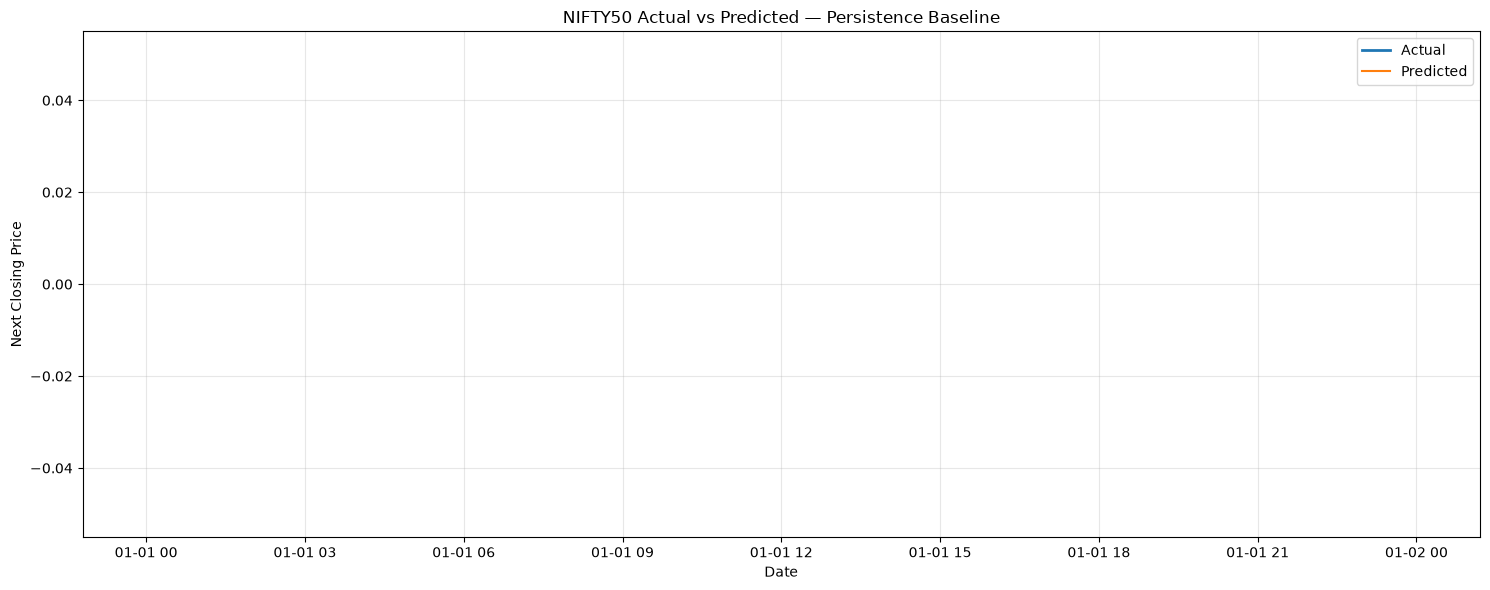

In [22]:
# Actual vs predicted values for NIFTY50
nifty_predictions = walk_forward_predictions_df[
    walk_forward_predictions_df["Instrument"] == "NIFTY50"
]

if not nifty_predictions.empty:

    best_nifty_model = (
        best_models.loc[
            best_models["Instrument"] == "NIFTY50",
            "Best_Model"
        ].iloc[0]
    )

    plot_data = nifty_predictions[
        nifty_predictions["Model"] == best_nifty_model
    ].sort_values("Date")

    plt.figure(figsize=(15, 6))

    plt.plot(
        plot_data["Date"],
        plot_data["Actual_Next_Close"],
        label="Actual",
        linewidth=2
    )

    plt.plot(
        plot_data["Date"],
        plot_data["Predicted_Next_Close"],
        label="Predicted",
        linewidth=1.5
    )

    plt.title(
        f"NIFTY50 Actual vs Predicted — {best_nifty_model}"
    )
    plt.xlabel("Date")
    plt.ylabel("Next Closing Price")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "nifty50_walk_forward_actual_vs_predicted.png",
        dpi=300
    )

    plt.show()

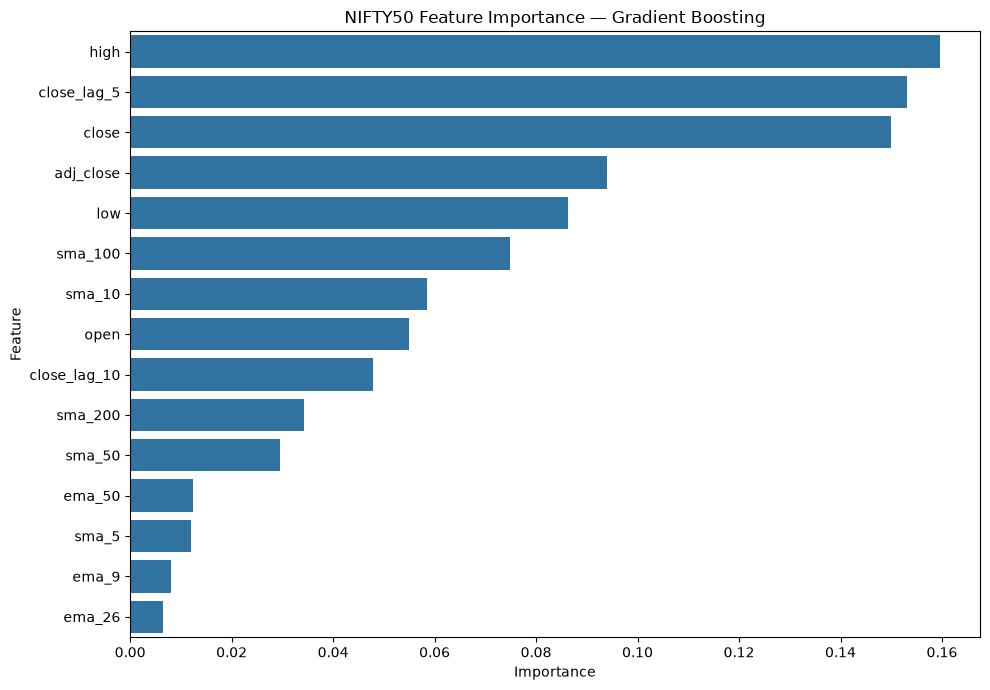

,Instrument,Model,Feature,Importance
11,BANKNIFTY,Decision Tree,close_lag_1,0.743332
10,BANKNIFTY,Decision Tree,close,0.211010
0,BANKNIFTY,Decision Tree,adj_close,0.029423
27,BANKNIFTY,Decision Tree,low,0.005426
24,BANKNIFTY,Decision Tree,high,0.004767
46,BANKNIFTY,Decision Tree,sma_200,0.002503
31,BANKNIFTY,Decision Tree,macd_signal,0.000398
52,BANKNIFTY,Decision Tree,volatility_20,0.000211
45,BANKNIFTY,Decision Tree,sma_20,0.000165
29,BANKNIFTY,Decision Tree,macd,0.000146


In [23]:
if not feature_importance_df.empty:

    importance_summary = (
        feature_importance_df
        .groupby(["Instrument", "Model", "Feature"])["Importance"]
        .mean()
        .reset_index()
    )

    importance_summary = importance_summary.sort_values(
        ["Instrument", "Model", "Importance"],
        ascending=[True, True, False]
    )

    importance_summary.to_csv(
        REPORT_DIR / "average_feature_importance.csv",
        index=False
    )

    nifty_importance = importance_summary[
        (importance_summary["Instrument"] == "NIFTY50")
        & (
            importance_summary["Model"].isin([
                "Random Forest",
                "Gradient Boosting",
                "XGBoost"
            ])
        )
    ]

    if not nifty_importance.empty:

        selected_importance_model = (
            nifty_importance["Model"].iloc[0]
        )

        plot_importance = (
            nifty_importance[
                nifty_importance["Model"]
                == selected_importance_model
            ]
            .nlargest(15, "Importance")
        )

        plt.figure(figsize=(10, 7))

        sns.barplot(
            data=plot_importance,
            x="Importance",
            y="Feature"
        )

        plt.title(
            f"NIFTY50 Feature Importance — "
            f"{selected_importance_model}"
        )

        plt.tight_layout()

        plt.savefig(
            CHART_DIR / "nifty50_feature_importance.png",
            dpi=300
        )

        plt.show()

    display(importance_summary.head(20))

else:
    print("No feature importance records were generated.")

In [24]:
final_model_records = []

for symbol, dataset in market_datasets.items():

    selected = best_models[
        best_models["Instrument"] == symbol
    ]

    if selected.empty:
        print(f"{symbol}: No selected model.")
        continue

    selected_model_name = selected["Best_Model"].iloc[0]

    if selected_model_name == "Persistence Baseline":
        print(
            f"{symbol}: Persistence baseline selected. "
            "No ML model will be saved."
        )
        continue

    if selected_model_name not in models:
        print(
            f"{symbol}: Model {selected_model_name} unavailable."
        )
        continue

    final_model = create_models()[selected_model_name]

    X = dataset["X"]
    y = dataset["y"]

    try:
        final_model.fit(X, y)

        model_path = (
            MODEL_DIR / f"{symbol}_{selected_model_name.replace(' ', '_')}.joblib"
        )

        joblib.dump(final_model, model_path)

        feature_path = (
            MODEL_DIR / f"{symbol}_model_features.json"
        )

        with open(feature_path, "w", encoding="utf-8") as file:
            json.dump(
                dataset["features"],
                file,
                indent=4
            )

        final_model_records.append({
            "Instrument": symbol,
            "Selected_Model": selected_model_name,
            "Training_Rows": len(X),
            "Feature_Count": len(dataset["features"]),
            "Model_File": str(model_path),
            "Feature_File": str(feature_path)
        })

        print(
            f"{symbol}: saved {selected_model_name}"
        )

    except Exception as error:
        print(
            f"{symbol}: final model training failed — {error}"
        )


final_model_summary = pd.DataFrame(final_model_records)

final_model_summary.to_csv(
    REPORT_DIR / "final_saved_models.csv",
    index=False
)

display(final_model_summary)

NIFTY50: Persistence baseline selected. No ML model will be saved.
BANKNIFTY: Persistence baseline selected. No ML model will be saved.
RELIANCE: Persistence baseline selected. No ML model will be saved.
TCS: Persistence baseline selected. No ML model will be saved.
HDFCBANK: Persistence baseline selected. No ML model will be saved.
INFY: Persistence baseline selected. No ML model will be saved.
ICICIBANK: Persistence baseline selected. No ML model will be saved.
SBIN: Persistence baseline selected. No ML model will be saved.
ITC: Persistence baseline selected. No ML model will be saved.
LT: Persistence baseline selected. No ML model will be saved.


""


In [25]:
print("=" * 70)
print("BHARATMARKET AI — NOTEBOOK 08 SUMMARY")
print("=" * 70)

print("\nInstruments loaded:", len(market_datasets))
print("Models evaluated:", len(models))
print("Validation folds:", N_SPLITS)

print(
    "\nTotal evaluation records:",
    len(walk_forward_df)
)

print(
    "Total prediction records:",
    len(walk_forward_predictions_df)
)

print(
    "\nInstruments evaluated:"
)

display(
    walk_forward_df.groupby("Instrument").agg(
        Folds=("Fold", "nunique"),
        Models=("Model", "nunique"),
        Evaluation_Rows=("RMSE", "count")
    )
)

print("\nBest models:")
display(best_models)

print("\nSaved model files:")
display(final_model_summary)

print("\nReports saved in:")
print(REPORT_DIR)

print("\nCharts saved in:")
print(CHART_DIR)

print("\nModels saved in:")
print(MODEL_DIR)

print("\nNotebook 08 execution completed.")

BHARATMARKET AI — NOTEBOOK 08 SUMMARY

Instruments loaded: 10
Models evaluated: 5
Validation folds: 6

Total evaluation records: 360
Total prediction records: 10390

Instruments evaluated:


,Folds,Models,Evaluation_Rows
Instrument,,,
BANKNIFTY,6,6,36
HDFCBANK,6,6,36
ICICIBANK,6,6,36
INFY,6,6,36
ITC,6,6,36
LT,6,6,36
NIFTY50,6,6,36
RELIANCE,6,6,36
SBIN,6,6,36



Best models:


,Instrument,Best_Model,Mean_RMSE
0,BANKNIFTY,Persistence Baseline,664.688814
1,HDFCBANK,Persistence Baseline,12.178994
2,ICICIBANK,Persistence Baseline,18.621060
3,INFY,Persistence Baseline,24.959613
4,ITC,Persistence Baseline,3.966633
5,LT,Persistence Baseline,62.839851
6,NIFTY50,Persistence Baseline,222.340956
7,RELIANCE,Persistence Baseline,20.105336
8,SBIN,Persistence Baseline,16.918146
9,TCS,Persistence Baseline,48.638510



Saved model files:


""



Reports saved in:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports

Charts saved in:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\charts

Models saved in:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\models

Notebook 08 execution completed.
